# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [1]:
VARIANT = 10   # порядковый номер в списке группы: Кныш Радион Николаевич, вариант 10
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))


среда: local | папка данных: D:\Computer vision\cv-2026-knysh\data
Вариант 10 уже на месте: D:\Computer vision\cv-2026-knysh\data\variant_10


данные варианта: D:\Computer vision\cv-2026-knysh\data\variant_10
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 5.0.0 | numpy 2.4.6 | pandas 3.1.0


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [3]:
# Читаем variant.json и выводим его содержимое
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(json.dumps(variant_info, indent=2, ensure_ascii=False))

# Читаем labels.csv в DataFrame labels и выводим первые строки
labels = pd.read_csv(DATA_DIR / "labels.csv")
labels.head()


{
  "variant": 10,
  "dataset_version": "v1",
  "source": "release",
  "breeds": [
    "Abyssinian",
    "Bengal",
    "scottish_terrier",
    "wheaten_terrier"
  ],
  "species": {
    "Abyssinian": "cat",
    "Bengal": "cat",
    "scottish_terrier": "dog",
    "wheaten_terrier": "dog"
  },
  "class_ids": {
    "Abyssinian": 0,
    "Bengal": 1,
    "scottish_terrier": 2,
    "wheaten_terrier": 3
  },
  "names_ru": {
    "Abyssinian": "абиссинская кошка",
    "Bengal": "бенгальская кошка",
    "scottish_terrier": "скотч-терьер",
    "wheaten_terrier": "ирландский мягкошёрстный пшеничный терьер"
  },
  "n_images": 798,
  "n_boxes": 397,
  "n_trimaps": 798,
  "per_breed": {
    "Abyssinian": {
      "images": 199,
      "boxes": 99,
      "trimaps": 199
    },
    "Bengal": {
      "images": 200,
      "boxes": 98,
      "trimaps": 200
    },
    "scottish_terrier": {
      "images": 199,
      "boxes": 100,
      "trimaps": 199
    },
    "wheaten_terrier": {
      "images": 200,
      "

,filename,breed,species,class_id
0,Abyssinian_1.jpg,Abyssinian,cat,0
1,Abyssinian_2.jpg,Abyssinian,cat,0
2,Abyssinian_3.jpg,Abyssinian,cat,0
3,Abyssinian_4.jpg,Abyssinian,cat,0
4,Abyssinian_5.jpg,Abyssinian,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [4]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print("Выбранный пример:", example_name)

# Читаем файл через cv2.imread
bgr = cv2.imread(str(example_path))

# Выводим type, shape, dtype, min, max и значение центрального пикселя
print("type:        ", type(bgr))
print("shape:       ", bgr.shape)
print("dtype:       ", bgr.dtype)
print("min / max:   ", bgr.min(), "/", bgr.max())

center_y, center_x = bgr.shape[0] // 2, bgr.shape[1] // 2
print(f"пиксель в центре ({center_y}, {center_x}) [B, G, R]:", bgr[center_y, center_x])


Выбранный пример: Abyssinian_155.jpg
type:         <class 'numpy.ndarray'>
shape:        (371, 581, 3)
dtype:        uint8
min / max:    0 / 230
пиксель в центре (185, 290) [B, G, R]: [  0  74 130]


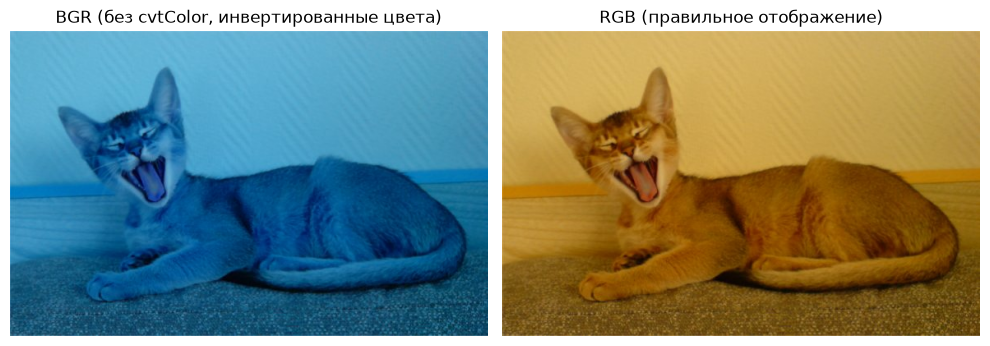

In [5]:
# Переводим bgr в rgb через cv2.cvtColor(..., cv2.COLOR_BGR2RGB)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# Показываем bgr и rgb рядом для наглядного сравнения каналов
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.title("BGR (без cvtColor, инвертированные цвета)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.title("RGB (правильное отображение)")
plt.axis("off")

plt.tight_layout()
plt.show()


Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [6]:
# Получаем gray, resized (224x224) и flipped, выводим их shape
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)

print("gray shape:   ", gray.shape)
print("resized shape:", resized.shape)
print("flipped shape:", flipped.shape)


gray shape:    (371, 581)
resized shape: (224, 224, 3)
flipped shape: (371, 581, 3)


In [7]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


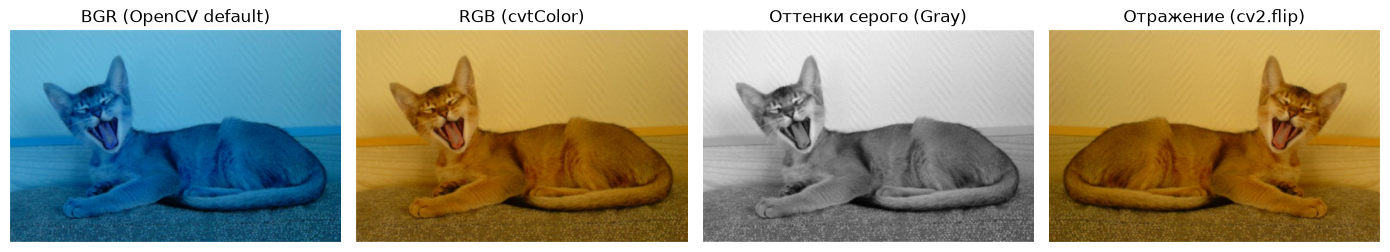

In [8]:
# 4 панели на одной фигуре: BGR как есть, RGB, серое, отражение
plt.figure(figsize=(14, 3.5))

plt.subplot(1, 4, 1)
plt.imshow(bgr)
plt.title("BGR (OpenCV default)")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(rgb)
plt.title("RGB (cvtColor)")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(gray, cmap="gray")
plt.title("Оттенки серого (Gray)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(flipped)
plt.title("Отражение (cv2.flip)")
plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110, bbox_inches="tight")
plt.show()


## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [9]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    # Через Image.open(p) получаем pil_format, mode, width, height
    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"] = im.width
        rec["height"] = im.height

    # has_xml: существует ли XML_DIR / (p.stem + ".xml")
    rec["has_xml"] = (XML_DIR / f"{p.stem}.xml").exists()

    # breed и species из label_by_file.loc[p.name]
    row_lbl = label_by_file.loc[p.name]
    rec["breed"] = row_lbl["breed"]
    rec["species"] = row_lbl["species"]

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()


,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Abyssinian_1.jpg,.jpg,JPEG,RGB,600,400,True,Abyssinian,cat
1,Abyssinian_10.jpg,.jpg,JPEG,RGB,375,500,True,Abyssinian,cat
2,Abyssinian_100.jpg,.jpg,JPEG,RGB,394,500,True,Abyssinian,cat
3,Abyssinian_101.jpg,.jpg,JPEG,RGB,450,313,True,Abyssinian,cat
4,Abyssinian_102.jpg,.jpg,JPEG,RGB,500,465,True,Abyssinian,cat


In [10]:
# Сводка с главными числами варианта
summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": int(info["breed"].nunique()),
    "n_cats": int((info["species"] == "cat").sum()),
    "n_dogs": int((info["species"] == "dog").sum()),
    "min_width": int(info["width"].min()),
    "median_width": float(info["width"].median()),
    "max_width": int(info["width"].max()),
    "min_height": int(info["height"].min()),
    "median_height": float(info["height"].median()),
    "max_height": int(info["height"].max()),
    "n_non_rgb": int((info["mode"] != "RGB").sum()),
    "n_non_jpeg": int((info["pil_format"] != "JPEG").sum()),
    "n_with_xml": int(info["has_xml"].sum()),
}

summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df


,metric,value
0,variant,10.0
1,n_files,798.0
2,n_breeds,4.0
3,n_cats,399.0
4,n_dogs,399.0
5,min_width,150.0
6,median_width,500.0
7,max_width,1646.0
8,min_height,116.0
9,median_height,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [11]:
# Печатаем файлы с mode != "RGB" и файлы с pil_format != "JPEG"
non_rgb = info[info["mode"] != "RGB"][["filename", "ext", "mode", "pil_format", "width", "height"]]
print("Файлы с mode != 'RGB':")
print(non_rgb.to_string(index=False))

non_jpeg = info[info["pil_format"] != "JPEG"][["filename", "ext", "mode", "pil_format", "width", "height"]]
print("\nФайлы с pil_format != 'JPEG' (формат не совпадает с расширением):\n")
print(non_jpeg.to_string(index=False))


Файлы с mode != 'RGB':
        filename  ext mode pil_format  width  height
Abyssinian_5.jpg .jpg RGBA        PNG    200     150

Файлы с pil_format != 'JPEG' (формат не совпадает с расширением):

        filename  ext mode pil_format  width  height
Abyssinian_5.jpg .jpg RGBA        PNG    200     150


In [12]:
# Сравниваем формы массивов для проблемного файла
prob_filename = non_rgb.iloc[0]["filename"]
prob_path = IMG_DIR / prob_filename

img_default = cv2.imread(str(prob_path))
img_unchanged = cv2.imread(str(prob_path), cv2.IMREAD_UNCHANGED)

print(f"Проблемный файл: {prob_filename}")
print(f"cv2.imread(p).shape:                    {img_default.shape}  (3 канала BGR, альфа-канал отброшен)")
print(f"cv2.imread(p, cv2.IMREAD_UNCHANGED).shape: {img_unchanged.shape}  (4 канала BGRA, альфа-канал сохранён)")


Проблемный файл: Abyssinian_5.jpg
cv2.imread(p).shape:                    (150, 200, 3)  (3 канала BGR, альфа-канал отброшен)
cv2.imread(p, cv2.IMREAD_UNCHANGED).shape: (150, 200, 4)  (4 канала BGRA, альфа-канал сохранён)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [13]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

# Берём одно изображение с XML и выводим координаты боксов
sample_stem = "Abyssinian_1"
sample_xml = XML_DIR / f"{sample_stem}.xml"
boxes = read_boxes(sample_xml)
print(f"Боксы головы из XML для {sample_stem}: {boxes}")

# Читаем trimap и выводим уникальные значения
trimap_path = TRIMAP_DIR / f"{sample_stem}.png"
trimap = cv2.imread(str(trimap_path), cv2.IMREAD_UNCHANGED)
print(f"Уникальные значения trimap ({trimap_path.name}): {np.unique(trimap)}")
print("Значения маски trimap: 1 = животное, 2 = фон, 3 = контурная граница")


Боксы головы из XML для Abyssinian_1: [(333, 72, 425, 158)]
Уникальные значения trimap (Abyssinian_1.png): [1 2 3]
Значения маски trimap: 1 = животное, 2 = фон, 3 = контурная граница


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

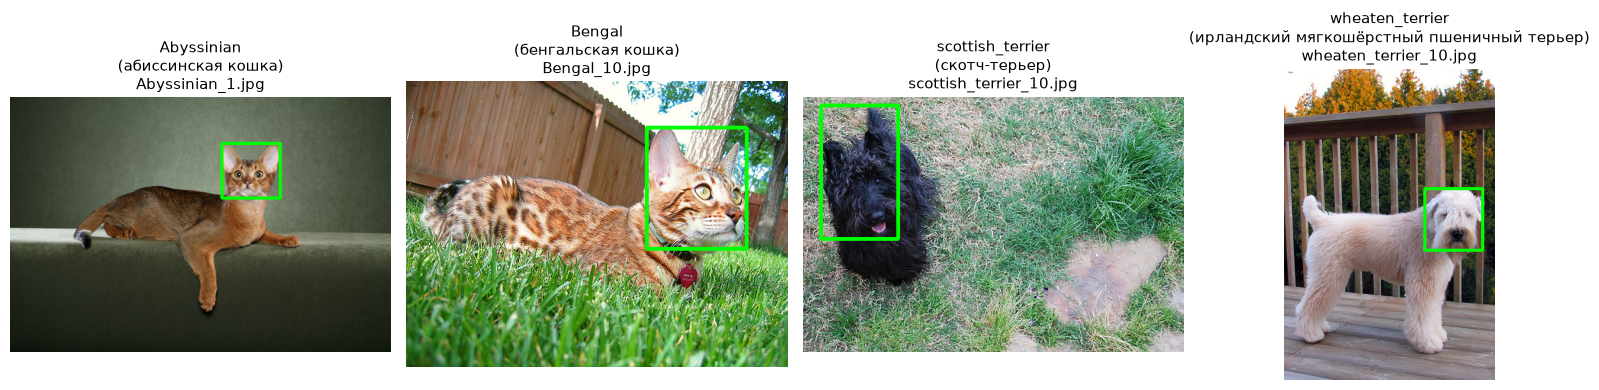

In [14]:
# Для каждой породы берём одно фото с XML, рисуем прямоугольник бокса головы
# и выводим сетку в один ряд, сохраняя в results/samples_grid.png
plt.figure(figsize=(16, 4))
breeds = variant_info["breeds"]

for idx, breed in enumerate(breeds):
    breed_rows = labels[labels["breed"] == breed]
    sample_file, sample_boxes = None, None
    for fn in breed_rows["filename"]:
        stem = Path(fn).stem
        xml_p = XML_DIR / f"{stem}.xml"
        if xml_p.exists():
            boxes = read_boxes(xml_p)
            if boxes:
                sample_file = fn
                sample_boxes = boxes
                break

    img_bgr = cv2.imread(str(IMG_DIR / sample_file))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    for xmin, ymin, xmax, ymax in sample_boxes:
        cv2.rectangle(img_rgb, (xmin, ymin), (xmax, ymax), (0, 255, 0), 3)

    plt.subplot(1, len(breeds), idx + 1)
    plt.imshow(img_rgb)
    ru_name = variant_info["names_ru"].get(breed, "")
    plt.title(f"{breed}\n({ru_name})\n{sample_file}", fontsize=11)
    plt.axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110, bbox_inches="tight")
plt.show()


## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [15]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

       metric  value
      variant   10.0
      n_files  798.0
     n_breeds    4.0
       n_cats  399.0
       n_dogs  399.0
    min_width  150.0
 median_width  500.0
    max_width 1646.0
   min_height  116.0
median_height  375.0
   max_height 1600.0
    n_non_rgb    1.0
   n_non_jpeg    1.0
   n_with_xml  397.0
не хватает: ничего, все 3 файла на месте


In [16]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)